# MMI 2x2 SiN 300 nm with BCB (85:15)

## 1. Device Overview

| Parameter | Specification |
|---|---|
| Device | 2x2 MMI coupler |
| Target splitting ratio | 15% direct / 85% cross |
| Target output phase difference | 90 degrees |
| Operating wavelength | 1.55 um |
| Band | 1.50-1.60 um |
| Core | SiN, 300 nm, constant n = 1.9729 |
| Stack | SiO2, SiN and BCB, air |
| Excited input | Upper input |

## 2. Interference mechanism and initial geometry

**Multimode interference**

The upper input excites the multimode region. The output waveguides are symmetrically positioned at y = +/-2.5 um.

The MMI and access waveguide polygons are built using `mmi_2x2_vertices()` from `upvfab_design_tools.tidy3d_plugin`.

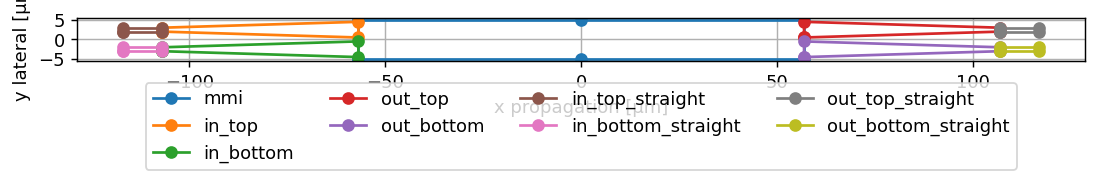

## 3. Design Flow

1. Use the geometry from the source simulation code: MMI length 113.71 um and taper length 50 um.
2. Build the SiO2/SiN/BCB/air stack and the 2x2 FDTD simulation with the package.
3. Excite the upper input and evaluate the output modes and wavelength sweep.

The source repository includes length and taper sweeps. The source introduction mentions 114.71 um, while its simulation code uses 113.71 um.

## 4. Simulation setup

### Numerical Parameters

| Parameter | Value |
|---|---|
| Backend | Tidy3D FDTD |
| `min_steps_per_wvl` | 15 |
| Maximum `run_time_s` | 8e-12 |
| Wavelength samples | 51 between 1.50 and 1.60 um |
| SiN refractive index | 1.9729, constant |
| BCB refractive index | 1.5779, constant |
| SiO2 permittivity | 2.085136 |
| Vertical stack | SiO2 to z=0; SiN z=0-0.3 um; BCB z=0-0.4 um; air above |

SiN has priority over BCB in their overlap, leaving 0.1 um of BCB above the core.

### Sources and Monitors

The upper input is excited. Mode and flux monitors are placed at each output and a field monitor records the core mid-plane. Source and monitor settings differ from the original notebook; the mode plane is centered at z=0.20 um instead of 0.15 um. The solver reached the field-decay shutoff threshold. Polarization of the selected source mode has not been independently verified.

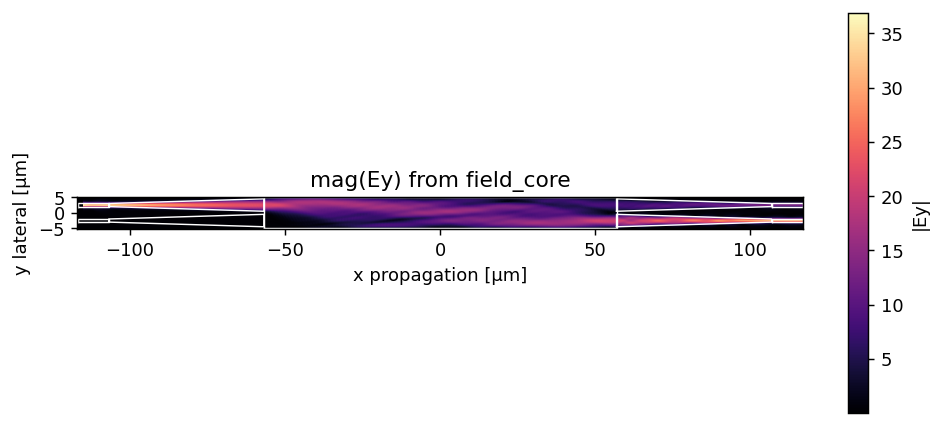

The simulation is built using `build_mmi_2x2_fdtd_simulation()`; the WIP notebook contains the model and saved-data loading.

## 5. Optimized geometry

The dimensions are the selected candidate defined by the source simulation code.

| Parameter | Value (um) |
|---|---|
| MMI length | 113.71 |
| MMI width | 10 |
| Input/output positions | +/-2.5 |
| Taper width | 4 |
| Taper length | 50 |
| Access width | 1 |
| Gap between tapers | 1 |
| Core thickness | 0.3 |
| BCB above core | 0.1 |

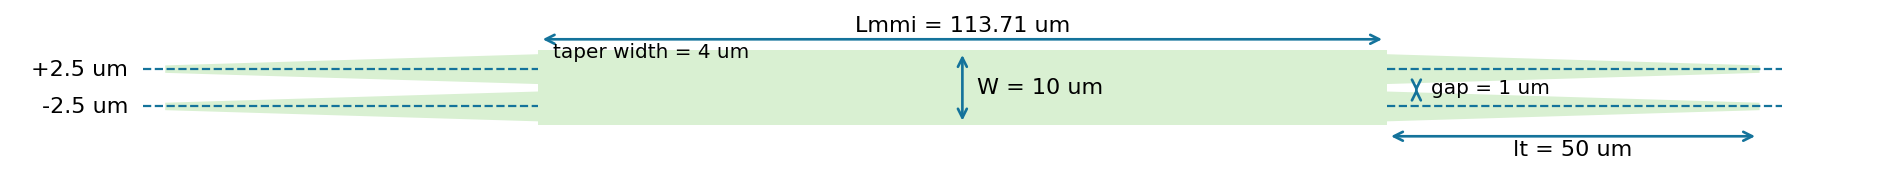

## 6. Results at $\lambda_0$ = 1.55 um

| Metric | Simulated value |
|---|---|
| Direct / cross splitting ratio | 14.7034 / 85.2966 % |
| Excess loss (dB) | 0.3241 |
| Output phase difference (degrees), cross minus direct | 89.58 |

The original notebook reports 14.7332 / 85.2668 %, 0.3141 dB and 89.54 degrees, with a final-decay warning. The source and monitor settings differ between the models.

## 7. Wavelength sweep results

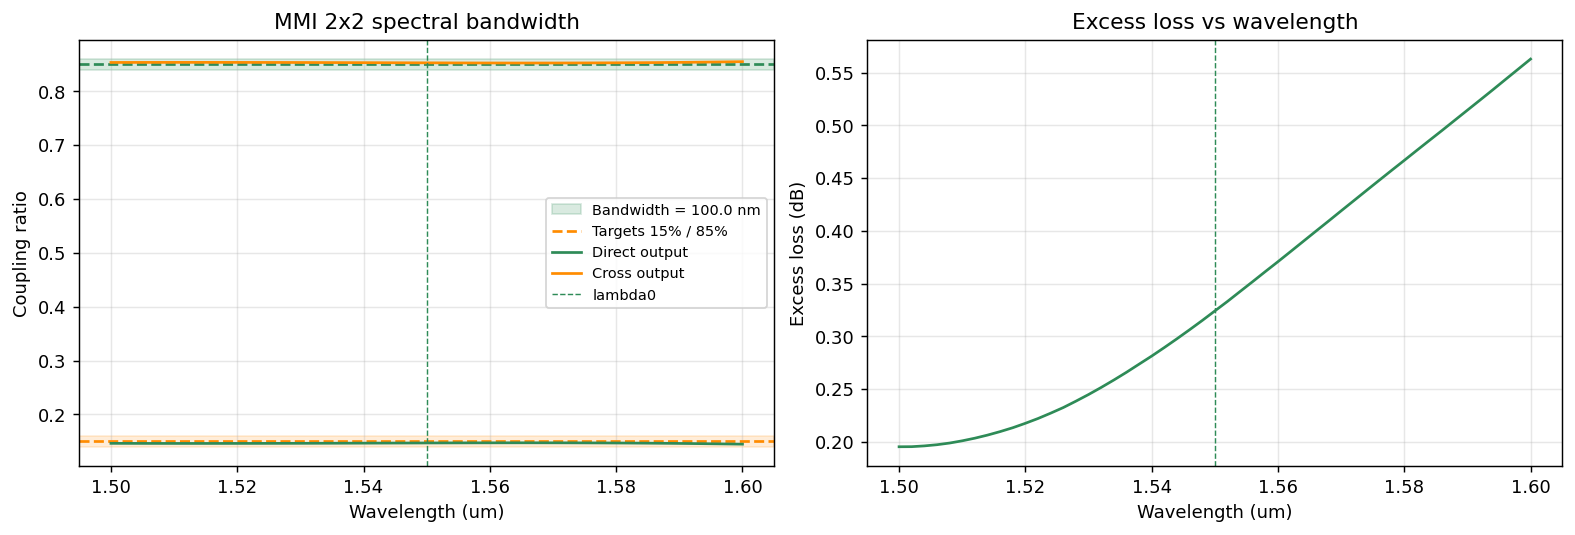

The 15:85 tolerance is +/-0.01 in coupling ratio. The criterion is met across the full sampled 1.50-1.60 um interval (100 nm); the response outside that interval was not evaluated.

Designer: Camilo Cano